# 01 · Customer lifecycle and the e-mail experiment: what the data can support

**Summary.** Both datasets can support their decision, with three findings that shape the modelling plan.
(1) **Data quality.** 22.5% of the 1.04M raw order lines have no customer ID (15.1% of gross sales), so the churn model
covers account customers only. After the ETL's rules, 805,830 lines from 5,875 customers remain (asserted against the
published count). The two largest orders (80,995 and 74,215 units) were cancelled the same day, which is why spend is
kept net of cancellations. (2) **Churn is seasonal.** The share of the 12-month base with no order in the next 90 days
runs from 42% (Sep 2010 snapshot) to 67% (Dec 2010 and Jan 2011). The Mar and Jun 2011 training snapshots sit at 63%;
the Sep 2011 test snapshot (50%) runs into the Christmas season. A model trained in spring will over-predict churn in
autumn, so notebook 02 must check calibration out of time. Moving the window to 60 or 120 days flips 6-8% of labels; 90
days is kept. (3) **The e-mail test is a valid randomised experiment** (sample-ratio p = 0.90, largest |SMD| 0.014,
arm-prediction AUC 0.50). The Mens e-mail lifts visits by 7.7 points (95% CI 7.0-8.3) and spend by $0.77 per customer
(0.49-1.05). Only 0.9% of customers buy anything, so individual targeting should rank on visit, not spend.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

## 1. Business understanding

A CVM team has two recurring decisions. This repo answers each with the public dataset that fits it (no public dataset
has both a long purchase history and a randomised offer test).

| | Retention budget | Offer choice |
|---|---|---|
| Decision | Which active customers get a retention contact next quarter | Which e-mail (Mens, Womens, none) each customer gets |
| Data | UCI Online Retail II: every order line of a UK gift wholesaler, Dec 2009 - Dec 2011 | Hillstrom: 64,000 customers randomised 1/3 each to Mens, Womens or no e-mail |
| Unit | Customer with an order in the 365 days before a snapshot date | Customer in the test |
| Target | Churn = no order in the 90 days after the snapshot | Visit (and spend) in the two weeks after the e-mail |
| Action | Contact the top k% by churn risk | Send the offer with the highest predicted uplift, or none |
| Success metric | Margin retained minus offer cost, per quarter | Incremental spend per 1,000 customers vs no e-mail |
| Constraints | Contact budget; offers cost money and may train customers to wait for discounts | Uplift must be measured against a control, not inferred from response |

This notebook checks what each dataset can support before any model is fitted: data quality, how churn is defined and
how much the definition matters, and whether the experiment is a valid randomised test.

## 2. Online Retail II: transaction audit

The ETL caches both workbook sheets as one table (the sheets overlap on 1-9 Dec 2010; that week is kept once).
Start with a column profile of the raw lines.

In [2]:
raw = F.load_raw_lines()
audit.profile(raw)

,dtype,non_null,missing_pct,unique,min,median,max,top,zeros_pct
column,,,,,,,,,
Invoice,str,1044848,0.0000,53628,None,NaN,None,573585,NaN
StockCode,str,1044848,0.0000,5305,None,NaN,None,85123A,NaN
Description,object,1040573,0.4100,5698,None,NaN,None,WHITE HANGING HEART T-LIGHT HOLDER,NaN
Quantity,int64,1044848,0.0000,1057,-80995,3.0000,80995,NaN,0.0000
InvoiceDate,datetime64[us],1044848,0.0000,47635,2009-12-01 07:45:00,NaN,2011-12-09 12:50:00,2011-10-31 14:41:00,NaN
Price,float64,1044848,0.0000,2807,"-53,594.3600",2.1000,"38,970.0000",NaN,0.5800
Customer ID,float64,809561,22.5200,5942,"12,346.0000","15,248.0000","18,287.0000",NaN,0.0000
Country,str,1044848,0.0000,43,None,NaN,None,United Kingdom,NaN


Before deciding what to drop, size every known data problem on the raw lines: how many lines it touches and how much of
gross sales it represents.

In [3]:
r = raw.rename(columns={"Customer ID": "CustomerID"})
r["Revenue"] = r["Quantity"] * r["Price"]
is_c = r["Invoice"].astype(str).str.startswith("C")
gross = r.loc[r["Revenue"] > 0, "Revenue"].sum()
checks = {
    "Cancellation lines (invoice starts with C)": is_c,
    "Negative quantity, not a cancellation": (r["Quantity"] < 0) & ~is_c,
    "Price zero": r["Price"] == 0,
    "Price negative (bad-debt adjustments)": r["Price"] < 0,
    "No customer ID": r["CustomerID"].isna(),
    "Exact duplicate of another line": r.duplicated(),
}
issues = pd.DataFrame({k: {"lines": int(m.sum()), "share_of_lines": m.mean(),
                           "share_of_gross_sales": r.loc[m & (r["Revenue"] > 0), "Revenue"].sum() / gross} for k, m in checks.items()}).T
issues["lines"] = issues["lines"].astype(int)
print(f"{len(r):,} raw lines, {r['Invoice'].nunique():,} invoices, gross sales £{gross / 1e6:,.1f}M")
issues

1,044,848 raw lines, 53,628 invoices, gross sales £20.5M


,lines,share_of_lines,share_of_gross_sales
Cancellation lines (invoice starts with C),19165,0.0183,0.0000
"Negative quantity, not a cancellation",3393,0.0032,0.0000
Price zero,6024,0.0058,0.0000
Price negative (bad-debt adjustments),5,0.0000,0.0000
No customer ID,235287,0.2252,0.1511
Exact duplicate of another line,11812,0.0113,0.0028


Missing customer IDs dominate: 235,287 lines (22.5%) and 15.1% of gross sales cannot be tied to a customer. Cancellations
are 1.8% of lines. Exact duplicates are 1.1% of lines but only 0.3% of sales.

Two of these need a closer look before choosing a rule.

* **Negative quantities that are not cancellations**: are they stock write-offs or customer returns?
* **Extreme quantities**: are the largest lines genuine orders, or mistakes that were reversed?

In [4]:
neg = r[(r["Quantity"] < 0) & ~is_c]
print(f"Negative-quantity non-cancellation lines: {len(neg):,}; with a customer ID: {neg['CustomerID'].notna().sum()}; "
      f"price > 0: {(neg['Price'] > 0).sum()}")
print("Most common descriptions:", ", ".join(neg["Description"].dropna().str.lower().value_counts().head(6).index))

big = r[~is_c & r["CustomerID"].notna()].nlargest(8, "Quantity")[["CustomerID", "StockCode", "Quantity", "Price", "InvoiceDate"]]
canc = r[is_c][["CustomerID", "StockCode", "Quantity", "InvoiceDate"]].rename(columns={"Quantity": "CancelQty", "InvoiceDate": "CancelDate"})
canc["Quantity"] = -canc["CancelQty"]
big = big.merge(canc, on=["CustomerID", "StockCode", "Quantity"], how="left")
big["reversed_within_days"] = (big["CancelDate"] - big["InvoiceDate"]).dt.days
big["line_value_gbp"] = big["Quantity"] * big["Price"]
big[["Quantity", "line_value_gbp", "reversed_within_days"]].assign(Customer="(anonymised)")

Negative-quantity non-cancellation lines: 3,393; with a customer ID: 0; price > 0: 0
Most common descriptions: check, damaged, damages, ?, missing, sold as set on dotcom


,Quantity,line_value_gbp,reversed_within_days,Customer
0,80995,"168,469.6000",0.0000,(anonymised)
1,74215,"77,183.6000",0.0000,(anonymised)
2,19152,"1,915.2000",NaN,(anonymised)
3,12960,"1,296.0000",NaN,(anonymised)
4,12960,"1,296.0000",NaN,(anonymised)
5,12744,"1,274.4000",NaN,(anonymised)
6,12540,0.0000,NaN,(anonymised)
7,12480,"1,248.0000",NaN,(anonymised)


All 3,393 negative-quantity lines outside cancellations have no customer ID and a zero price, with descriptions such as
"damaged" and "missing". They are warehouse write-offs, and the customer-ID rule removes them. The two largest orders
(80,995 and 74,215 units, £168K and £77K) were cancelled the same day. The next largest (12,000-19,000 units at about
£0.10 each) are plausible wholesale orders and are kept.

Now apply the ETL's cleaning rules one at a time, with row counts after each step. Cancellations are kept on purpose:
they carry negative quantities, so spend is measured net of returns, and the very large orders above net to zero.

In [5]:
lines, steps = F.clean_lines(raw)
orders = F.build_orders(lines)
assert len(lines) == 805_830                       # the ETL's published clean-line count (ml/metrics.json)
dup_clean = lines.duplicated(subset=["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "CustomerID"])
print(f"After cleaning: {len(lines):,} lines, {lines['Invoice'].nunique():,} invoices, {orders['Invoice'].nunique():,} purchase orders, "
      f"{lines['CustomerID'].nunique():,} customers, {lines['IsCancel'].mean():.1%} cancellation lines")
print(f"Exact duplicate lines still present: {dup_clean.sum():,} ({dup_clean.mean():.2%} of lines, "
      f"{lines.loc[dup_clean & (lines['Revenue'] > 0), 'Revenue'].sum() / lines.loc[lines['Revenue'] > 0, 'Revenue'].sum():.2%} of gross sales)")
steps

After cleaning: 805,830 lines, 43,876 invoices, 36,594 purchase orders, 5,875 customers, 2.2% cancellation lines
Exact duplicate lines still present: 11,665 (1.45% of lines, 0.33% of gross sales)


,rows,removed,share_of_raw
step,,,
"Raw lines (both sheets, overlap week de-duplicated)",1044848,0,1.0000
Drop lines without a customer ID,809561,235287,0.7748
"Drop zero and negative prices (bad debt, free samples)",809491,70,0.7747
"Drop non-product codes (postage, fees, manual adjustments, vouchers)",805830,3661,0.7712


The customer-ID rule removes 235,287 lines. The price rule removes 70 more (most zero-price lines have no customer), and the
non-product rule removes 3,661. That leaves 805,830 lines, 36,594 purchase orders and 5,875 customers.

**Cleaning decisions.**

* Lines without a customer ID cannot be attributed to anyone, so they cannot feed a customer-level model. They are a
  large share of lines but a smaller share of sales; the model describes identified (account) customers only.
* Zero and negative prices are write-offs and bad-debt adjustments, not purchases.
* Postage, bank charges, Amazon fees, manual adjustments and gift vouchers are not products.
* Exact duplicate lines are kept, as in the ETL. They can be genuine repeat scans on one invoice and they never change
  whether an order exists, so the churn label is unaffected; they move spend features by well under 1%.

Does the duplicate decision change anything that matters? Rebuild one snapshot without duplicates and compare.

In [6]:
s_dup = F.snapshot(lines, F.SNAPSHOTS["train"], orders)
dedup = lines[~dup_clean]
s_nodup = F.snapshot(dedup, F.SNAPSHOTS["train"], F.build_orders(dedup))
print(f"Customers: {len(s_dup):,} vs {len(s_nodup):,}; churn labels identical: {(s_dup['churn'] == s_nodup.loc[s_dup.index, 'churn']).all()}")
print(f"Median relative change in 12-month spend: {((s_dup['spend_365'] - s_nodup.loc[s_dup.index, 'spend_365']).abs() / s_dup['spend_365'].abs().clip(lower=1)).median():.4%}; "
      f"Spearman rho of spend_365 between versions: {s_dup['spend_365'].corr(s_nodup.loc[s_dup.index, 'spend_365'], method='spearman'):.4f}")

Customers: 4,260 vs 4,260; churn labels identical: True
Median relative change in 12-month spend: 0.0000%; Spearman rho of spend_365 between versions: 0.9998


The duplicate decision does not matter for the model. Labels are identical, and 12-month spend has a rank correlation of
0.9998 between the two versions.

## 3. The customer base over time

The ETL's lifecycle definition: a customer is **active** in a month if they bought in that month or the two before it.
Each month every customer in the base is New (first purchase), Retained, Reactivated (back after an inactive spell)
or Churned (active last month, not this month). The flows below are recomputed independently and match the published
`fact_customer_month.csv` exactly.

In [7]:
flows = F.monthly_flows(orders)
pub = pd.read_csv(ROOT / "data" / "fact_customer_month.csv", parse_dates=["MonthStart"]).groupby(["MonthStart", "Flow"]).size().unstack().fillna(0)
assert (flows[["New", "Retained", "Reactivated", "Churned"]].values == pub[["New", "Retained", "Reactivated", "Churned"]].values).all()
yr = flows.loc["2010-12-01":"2011-11-01"]
peak_m, trough_m = flows.loc[:"2011-06-01", "Active"].idxmax(), flows.loc[:"2011-06-01", "Active"].idxmin()
print(f"Dec 2010 - Nov 2011: {yr['New'].sum():,} new, {yr['Reactivated'].sum():,} reactivated, {yr['Churned'].sum():,} churned")
print(f"Active base: peak {flows['Active'].max():,} ({flows['Active'].idxmax():%b %Y}); "
      f"fell {1 - flows.loc['2011-01-01':'2011-04-01', 'Active'].min() / flows.loc['2010-11-01', 'Active']:.0%} from Nov 2010 to its spring 2011 low")
flows.T

Dec 2010 - Nov 2011: 1,585 new, 2,864 reactivated, 4,481 churned
Active base: peak 2,877 (Nov 2010); fell 42% from Nov 2010 to its spring 2011 low


month,2010-03-01,2010-04-01,2010-05-01,2010-06-01,2010-07-01,2010-08-01,2010-09-01,2010-10-01,2010-11-01,2010-12-01,...,2011-02-01,2011-03-01,2011-04-01,2011-05-01,2011-06-01,2011-07-01,2011-08-01,2011-09-01,2011-10-01,2011-11-01
New,441,294,255,267,185,163,239,375,326,76,...,125,179,106,111,108,101,107,188,221,191
Retained,1342,1577,1701,1670,1714,1655,1607,1800,2265,2494,...,1407,1322,1511,1619,1640,1713,1666,1626,1891,2240
Reactivated,0,65,91,103,108,136,205,327,286,95,...,148,273,255,261,240,210,171,341,361,414
Churned,352,206,235,377,326,352,347,251,237,383,...,810,358,263,253,351,275,358,318,264,233
Active,1783,1936,2047,2040,2007,1954,2051,2502,2877,2665,...,1680,1774,1872,1991,1988,2024,1944,2155,2473,2845


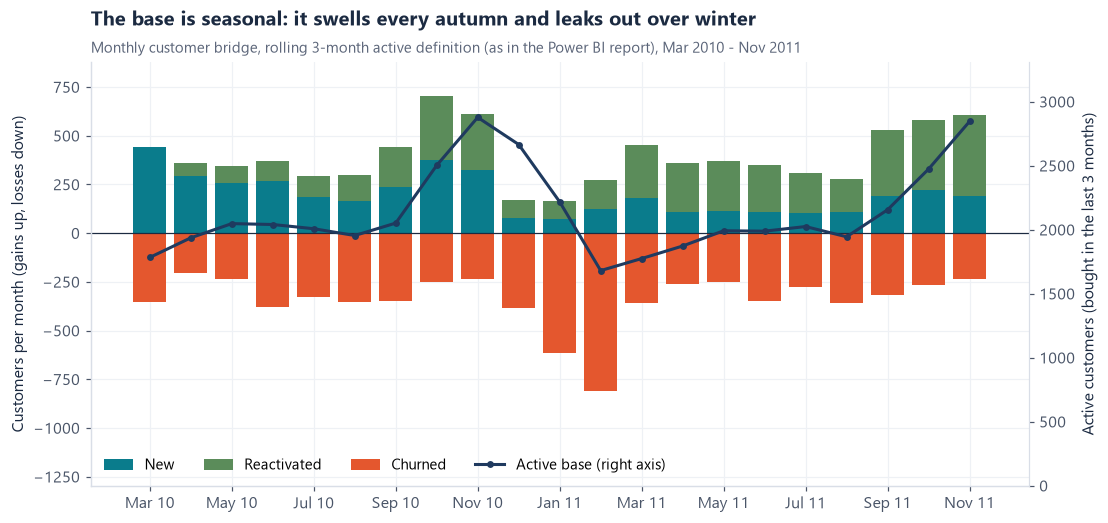

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(flows))
ax.bar(x, flows["New"], color=PALETTE["teal"], label="New")
ax.bar(x, flows["Reactivated"], bottom=flows["New"], color=PALETTE["sage"], label="Reactivated")
ax.bar(x, -flows["Churned"], color=PALETTE["coral"], label="Churned")
ax.axhline(0, color=PALETTE["ink"], lw=0.8)
ax.set_ylabel("Customers per month (gains up, losses down)")
ax2 = ax.twinx()
ax2.plot(x, flows["Active"], color=PALETTE["navy"], marker="o", ms=3.5, label="Active base (right axis)")
ax2.set_ylabel("Active customers (bought in the last 3 months)")
ax2.grid(False); ax2.spines["right"].set_visible(True); ax2.set_ylim(0, flows["Active"].max() * 1.15)
ax.set_xticks(x[::2], [m.strftime("%b %y") for m in flows.index[::2]])
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower left", ncol=4)
ax.set_ylim(-flows["Churned"].max() * 1.6, (flows["New"] + flows["Reactivated"]).max() * 1.25)
headline(ax, "The base is seasonal: it swells every autumn and leaks out over winter",
         "Monthly customer bridge, rolling 3-month active definition (as in the Power BI report), Mar 2010 - Nov 2011")
savefig(fig, "01-lifecycle", FIG); plt.show()

The base contracts every winter, from 2,877 active customers in Nov 2010 to 1,680 in Feb 2011 (-42%), and rebuilds in the
autumn. Most of the rebuilding is reactivation, not acquisition: 2,864 reactivated vs 1,585 new from Dec 2010 to Nov 2011.
A "churned" customer is often a seasonal buyer who comes back, so the value of a retention contact depends on the season
in which it is made.

Cohort view: of the customers whose first purchase was in a month, what share buys again k months later?

Cohorts Jan 2010 onwards (customer-weighted): 21.0% buy again in month 1, 18.4% in month 12
Dec 2009 'cohort' (951 customers): 35.0% in month 1, 37.6% in month 12


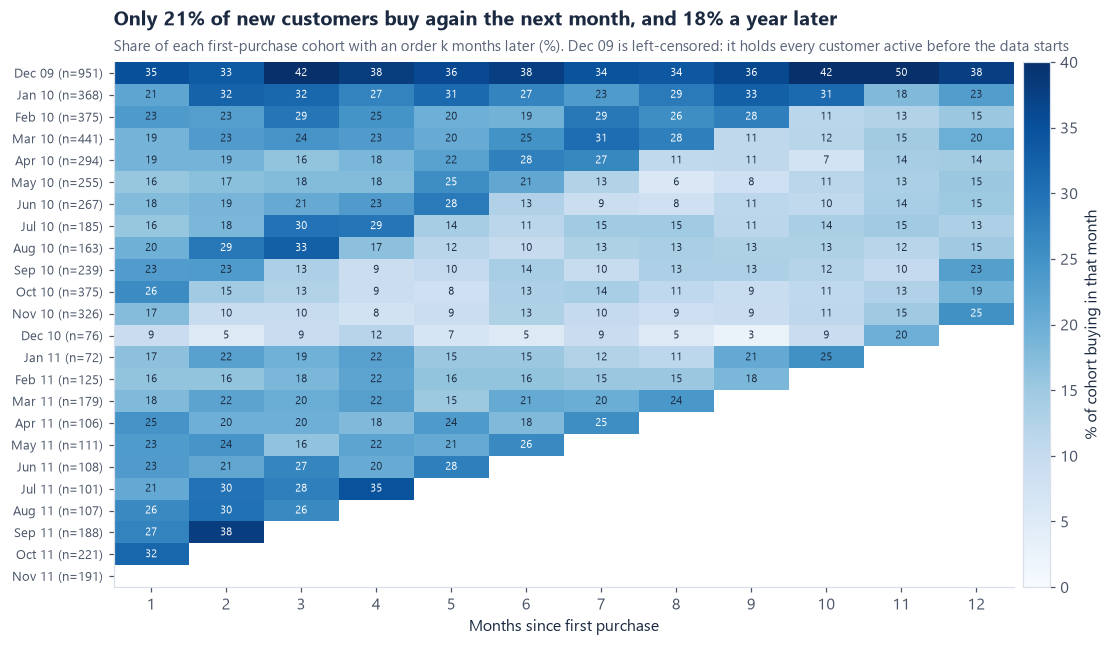

In [9]:
coh = F.cohort_matrix(orders)
first_n = orders.groupby("CustomerID")["Month"].min().value_counts().sort_index()


def weighted_return(k, cohorts):
    s = coh.loc[cohorts, k].dropna()
    return float((s * first_n[s.index]).sum() / first_n[s.index].sum())


later = coh.index[coh.index > "2009-12-01"]            # Dec 2009 is left-censored: it holds every customer active before the data starts
m1, m12 = weighted_return(1, later), weighted_return(12, later)
print(f"Cohorts Jan 2010 onwards (customer-weighted): {m1:.1%} buy again in month 1, {m12:.1%} in month 12")
print(f"Dec 2009 'cohort' ({first_n.iloc[0]:,} customers): {coh.iloc[0, 1]:.1%} in month 1, {coh.iloc[0, 12]:.1%} in month 12")

fig, ax = plt.subplots(figsize=(11, 6.2))
grid = coh.loc[:, 1:12] * 100
im = ax.imshow(grid.values, aspect="auto", cmap="Blues", vmin=0, vmax=40)
ax.set_xticks(range(12), [str(k) for k in range(1, 13)])
ax.set_yticks(range(len(grid)), [f"{m:%b %y} (n={first_n[m]:,})" for m in grid.index], fontsize=8.5)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white" if v > 25 else PALETTE["ink"])
ax.grid(False)
ax.set_xlabel("Months since first purchase")
plt.colorbar(im, ax=ax, fraction=0.03, pad=0.01, label="% of cohort buying in that month")
headline(ax, f"Only {m1:.0%} of new customers buy again the next month, and {m12:.0%} a year later",
         "Share of each first-purchase cohort with an order k months later (%). Dec 09 is left-censored: it holds every customer active before the data starts")
plt.show()

After the first month, repeat buying settles at around 15-20% of a cohort in any month. The autumn 2010 cohorts (Sep-Nov)
light up again at month 12, when they come back for the next Christmas season. The cohorts confirm the seasonality seen
in the bridge. The Dec 2009 row is not a real cohort: it holds every customer already active when the data starts.

## 4. The churn label: definition, seasonality and sensitivity

The model's unit is a customer with an order in the 365 days before snapshot date *t*; churn = no order in
[t, t + 90 days). Two questions before trusting it:

1. **Does the base rate move over time?** If it does, a model trained in one season will be miscalibrated in another.
2. **How much does the 90-day choice matter?** Compare 60 and 120 days: base rate and how many customers flip label.

Snapshots from Jun 2010 (six months of history behind them) to Jun 2011. The data ends on 9 Dec 2011, so a label is only
observable when t + window falls before that date; the 120-day label cannot be computed for the Sep 2011 test snapshot.

In [10]:
END = lines["Day"].max() + pd.Timedelta(days=1)
snap_dates = pd.date_range("2010-06-01", "2011-09-01", freq="MS")
rows = []
for t in snap_dates:
    s = F.snapshot(lines, t, orders)
    row = {"snapshot": t, "customers": len(s)}
    for w in (60, 90, 120):
        row[f"churn_{w}d"] = F.churn_label(orders, s.index, t, w).mean() if t + pd.Timedelta(days=w) <= END else np.nan
    rows.append(row)
rates = pd.DataFrame(rows).set_index("snapshot")
rates

,customers,churn_60d,churn_90d,churn_120d
snapshot,,,,
2010-06-01,2684,0.5842,0.5030,0.4303
2010-07-01,2951,0.6195,0.5114,0.4005
2010-08-01,3136,0.5969,0.4557,0.3638
2010-09-01,3299,0.5368,0.4168,0.3841
2010-10-01,3538,0.5127,0.4664,0.4415
2010-11-01,3913,0.6003,0.5571,0.5167
2010-12-01,4239,0.7334,0.6681,0.6067
2011-01-01,4205,0.7493,0.6694,0.6088
2011-02-01,4221,0.7276,0.6541,0.5942


The 90-day base rate moves by 25 points within a year: 42% for the Sep 2010 snapshot, 67% for Dec 2010 and Jan 2011, and
63% for the Mar and Jun 2011 training snapshots. The Sep 2011 test value (50%) is shown for reference only. Its
same-season analogue from 2010 (42%) was known on the scoring date and already pointed to a lower autumn rate.

In [11]:
sens = []
for name in ("train", "valid"):
    t = pd.Timestamp(F.SNAPSHOTS[name])
    s = F.snapshot(lines, t, orders)
    y90 = s["churn"].values
    for w in (60, 120):
        yw = F.churn_label(orders, s.index, t, w)
        sens.append({"snapshot": f"{name} ({t:%b %Y})", "window": f"{w} days", "base_rate": yw.mean(), "base_rate_90d": y90.mean(),
                     "flip_to_churn": int(((yw == 1) & (y90 == 0)).sum()), "flip_to_active": int(((yw == 0) & (y90 == 1)).sum()),
                     "share_flipped": (yw != y90).mean()})
sens = pd.DataFrame(sens).set_index(["snapshot", "window"])
sens

base_rate  base_rate_90d  flip_to_churn  flip_to_active  share_flipped
snapshot         window                                                                          
train (Mar 2011) 60 days      0.7110         0.6312            340               0         0.0798
                 120 days     0.5758         0.6312              0             236         0.0554
valid (Jun 2011) 60 days      0.6929         0.6337            256               0         0.0592
                 120 days     0.5624         0.6337              0             308         0.0712

A shorter window only adds churners and a longer one only removes them, as it must. At the Mar 2011 snapshot, a 60-day
window adds 340 churners (8.0% of the base) and a 120-day window removes 236 (5.5%). The model ranks customers, and these
flips sit near the boundary, so the ranking is unlikely to change much. The base rate, and with it calibration and the
value of a contact, does depend on the window.

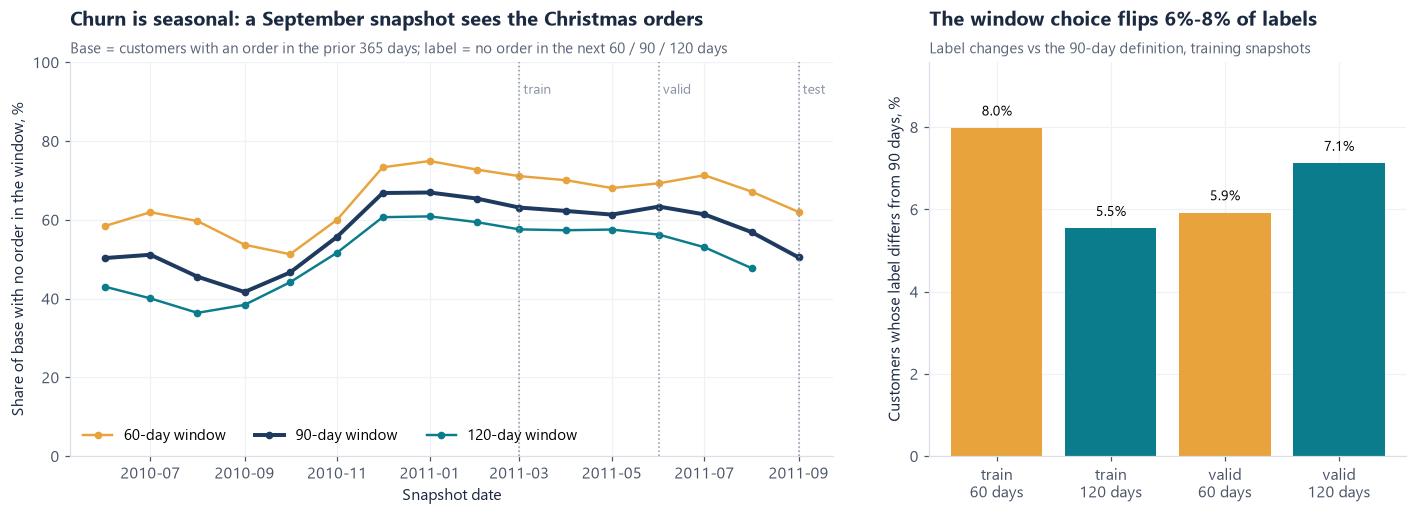

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
for w, c in ((60, PALETTE["amber"]), (90, PALETTE["navy"]), (120, PALETTE["teal"])):
    a1.plot(rates.index, rates[f"churn_{w}d"] * 100, marker="o", ms=4, color=c, label=f"{w}-day window", lw=2.6 if w == 90 else 1.6)
for name, t in F.SNAPSHOTS.items():
    a1.axvline(pd.Timestamp(t), color=PALETTE["grey"], ls=":", lw=1)
    a1.text(pd.Timestamp(t), 92, f" {name}", fontsize=9, color=PALETTE["grey"])
a1.set_ylim(0, 100); a1.set_ylabel("Share of base with no order in the window, %"); a1.legend(loc="lower left", ncol=3)
a1.set_xlabel("Snapshot date")
headline(a1, "Churn is seasonal: a September snapshot sees the Christmas orders",
         "Base = customers with an order in the prior 365 days; label = no order in the next 60 / 90 / 120 days")
sv = sens.reset_index()
lab = [f"{a.split(' ')[0]}\n{b}" for a, b in zip(sv["snapshot"], sv["window"])]
a2.bar(np.arange(len(sv)), sv["share_flipped"] * 100, color=[PALETTE["amber"] if "60" in w else PALETTE["teal"] for w in sv["window"]])
for i, v in enumerate(sv["share_flipped"] * 100):
    a2.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)
a2.set_xticks(np.arange(len(sv)), lab); a2.set_ylabel("Customers whose label differs from 90 days, %")
a2.set_ylim(0, sv["share_flipped"].max() * 100 * 1.2)
headline(a2, f"The window choice flips {sv['share_flipped'].min():.0%}-{sv['share_flipped'].max():.0%} of labels",
         "Label changes vs the 90-day definition, training snapshots")
fig.tight_layout()
savefig(fig, "01-churn-label", FIG); plt.show()

## 5. What predicts churn? Bivariate view on the training snapshots

Target-related EDA uses only the two training snapshots (Mar and Jun 2011). The Sep 2011 test snapshot's labels are
not looked at here, so nothing in the modelling plan is tuned on the test period.

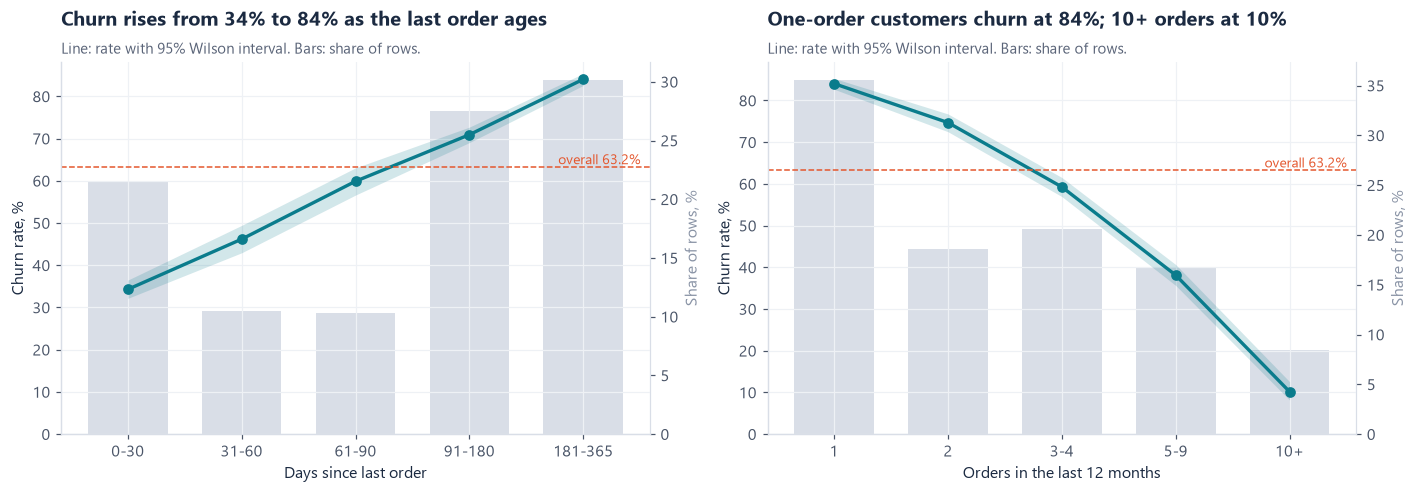

rows  share   rate  ci_low  ci_high
recency    0-30     1849 0.2154 0.3429  0.3216   0.3648
           31-60     903 0.1052 0.4618  0.4295   0.4944
           61-90     885 0.1031 0.5989  0.5662   0.6307
           91-180   2359 0.2748 0.7092  0.6905   0.7272
           181-365  2588 0.3015 0.8404  0.8258   0.8540
orders_365 1        3052 0.3555 0.8404  0.8270   0.8530
           2        1597 0.1860 0.7470  0.7251   0.7677
           3-4      1768 0.2060 0.5928  0.5697   0.6154
           5-9      1440 0.1678 0.3812  0.3565   0.4066
           10+       727 0.0847 0.1018  0.0819   0.1259

In [13]:
train = pd.concat([F.snapshot(lines, F.SNAPSHOTS[k], orders).assign(snapshot=k) for k in ("train", "valid")])
train["recency_band"] = eda.binned(train["recency_days"], bins=[0, 30, 60, 90, 180, 365], labels=["0-30", "31-60", "61-90", "91-180", "181-365"])
train["orders_band"] = eda.binned(train["orders_365"], bins=[0, 1, 2, 4, 9, 1e9], labels=["1", "2", "3-4", "5-9", "10+"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
rate = train.groupby("recency_band")["churn"].mean()
t_rec = eda.rate_by(train, "recency_band", "churn", ax=a1, order=["0-30", "31-60", "61-90", "91-180", "181-365"],
                    title=f"Churn rises from {rate['0-30']:.0%} to {rate['181-365']:.0%} as the last order ages",
                    xlabel="Days since last order", rate_label="Churn rate")
rate = train.groupby("orders_band")["churn"].mean()
t_frq = eda.rate_by(train, "orders_band", "churn", ax=a2, order=["1", "2", "3-4", "5-9", "10+"],
                    title=f"One-order customers churn at {rate['1']:.0%}; 10+ orders at {rate['10+']:.0%}",
                    xlabel="Orders in the last 12 months", rate_label="Churn rate")
fig.tight_layout()
plt.show()
pd.concat({"recency": t_rec, "orders_365": t_frq})

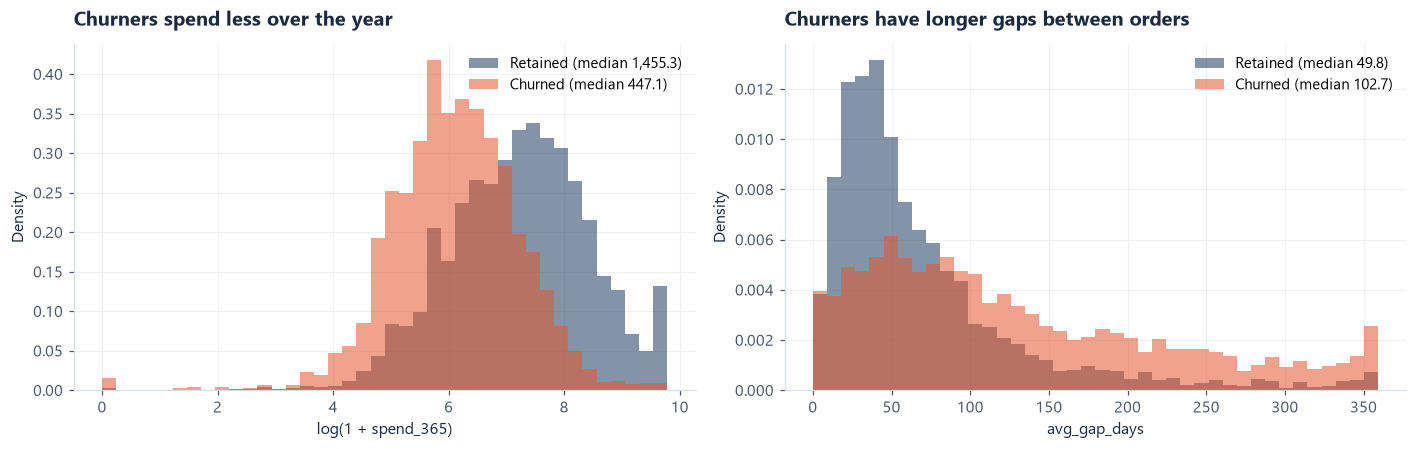

In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
eda.dist_by_target(train, "spend_365", "churn", ax=a1, log=True, title="Churners spend less over the year")
eda.dist_by_target(train, "avg_gap_days", "churn", ax=a2, title="Churners have longer gaps between orders")
fig.tight_layout(); plt.show()

Information value ranks the features on the training snapshots (a single-feature view; interactions come later).
The correlation matrix shows which features carry the same information.

In [15]:
iv = eda.iv_table(train, F.FEATS, "churn")
iv

,iv,strength
feature,,
orders_365,1.1104,suspicious (check leakage)
orders_all,1.0157,suspicious (check leakage)
spend_365,0.9815,suspicious (check leakage)
spend_90,0.8111,suspicious (check leakage)
orders_90,0.7543,suspicious (check leakage)
recency_days,0.7229,suspicious (check leakage)
avg_gap_days,0.5809,suspicious (check leakage)
products_365,0.5756,suspicious (check leakage)
spend_prev_90,0.5288,suspicious (check leakage)


The "suspicious" labels come from credit scoring, where an IV above 0.5 usually means leakage. Here strong IVs are
expected, because past buying is the classic predictor of future buying (RFM). Every feature is computed strictly before
the snapshot date (tested). Notebook 02 runs the formal leakage screen. `is_uk` carries no signal on its own (IV 0.002).

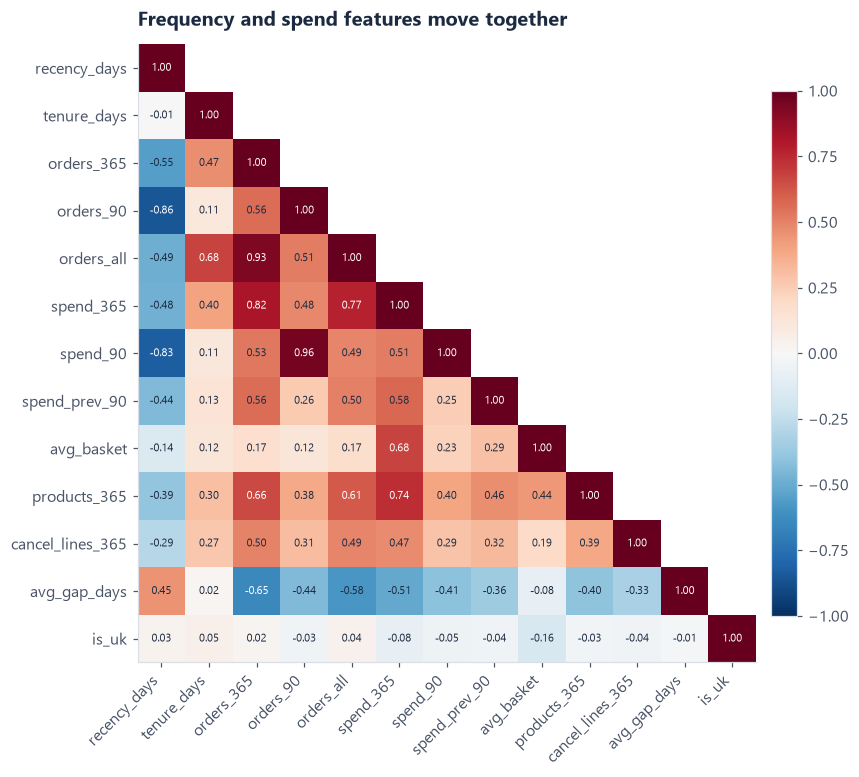

,feature_a,feature_b,rho
4,orders_90,spend_90,0.9580
2,orders_365,orders_all,0.9331
0,recency_days,orders_90,-0.8568
1,recency_days,spend_90,-0.8264
3,orders_365,spend_365,0.8165
5,orders_all,spend_365,0.7717


In [16]:
corr = eda.corr_heatmap(train, F.FEATS, title="Frequency and spend features move together")
plt.show()
eda.high_correlation_pairs(train, F.FEATS, threshold=0.75)

Six pairs exceed |rho| 0.75. Short-window frequency and spend move together (0.96), and so do 12-month and all-time orders
(0.93). Recency is the mirror image of 90-day activity (-0.86). These are three families (recency, frequency, spend) more
than 13 independent signals.

**When is each field known?** Every feature is computed from lines dated strictly before the snapshot date, and the
label from orders on or after it (tests/test_features.py proves that a purchase after *t* cannot change a feature at *t*).
One field needed care: the ETL takes a customer's country from their whole history, which can include purchases after
*t*. `features.snapshot` uses the history before *t* instead; 12 of 5,875 customers ever change country, and notebook 02
shows the published AUC is unchanged.

## 6. Hillstrom e-mail test: is it a valid randomised experiment?

64,000 customers who bought in the last 12 months were randomised to a Mens e-mail, a Womens e-mail or no e-mail;
visit, conversion and spend were tracked for two weeks. Before reading any outcome, check the randomisation:
the arm sizes (sample-ratio mismatch) and covariate balance (standardised mean differences).

In [17]:
h = F.load_hillstrom()
print(f"{len(h):,} customers, {h.shape[1]} columns; duplicate rows: {audit.duplicates(h.drop(columns=['Arm', 'ZipCode', 'Purchased', 'RecencyBand']))['exact_duplicate_rows']:,} "
      "(no customer key; identical covariate and outcome rows are expected in a 64K table of a few discrete fields)")
audit.profile(h[["recency", "history", "mens", "womens", "zip_code", "newbie", "channel", "segment", "visit", "conversion", "spend"]])

64,000 customers, 16 columns; duplicate rows: 6,562 (no customer key; identical covariate and outcome rows are expected in a 64K table of a few discrete fields)


,dtype,non_null,missing_pct,unique,min,median,max,top,zeros_pct
column,,,,,,,,,
recency,int64,64000,0.0000,12,1.0000,6.0000,12.0000,NaN,0.0000
history,float64,64000,0.0000,34833,29.9900,158.1100,"3,345.9300",NaN,0.0000
mens,int64,64000,0.0000,2,0.0000,1.0000,1.0000,NaN,44.9000
womens,int64,64000,0.0000,2,0.0000,1.0000,1.0000,NaN,45.0300
zip_code,str,64000,0.0000,3,NaN,NaN,NaN,Surburban,NaN
newbie,int64,64000,0.0000,2,0.0000,1.0000,1.0000,NaN,49.7800
channel,str,64000,0.0000,3,NaN,NaN,NaN,Web,NaN
segment,str,64000,0.0000,3,NaN,NaN,NaN,Womens E-Mail,NaN
visit,int64,64000,0.0000,2,0.0000,0.0000,1.0000,NaN,85.3200


In [18]:
from scipy import stats
counts = h["Arm"].value_counts().reindex(F.ARMS)
chi2, p_srm = stats.chisquare(counts.values)
print(f"Arm sizes: {dict(counts)}; SRM chi-square = {chi2:.2f}, p = {p_srm:.3f} (H0: 1/3 each)")

cov = pd.get_dummies(h[["recency", "history", "mens", "womens", "newbie", "ZipCode", "channel"]], columns=["ZipCode", "channel"], dtype=float)
cov["log_history"] = np.log1p(h["history"])


def smd(a: pd.DataFrame, b: pd.DataFrame) -> pd.Series:
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


ctrl = cov[h["Arm"] == "Control"]
bal = pd.DataFrame({t: smd(cov[h["Arm"] == t], ctrl) for t in F.TREATMENTS})
print(f"Largest |SMD|: {bal.abs().max().max():.3f} (a common balance threshold is 0.10)")

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
c2st = {t: cross_val_score(LogisticRegression(max_iter=2000), cov[h["Arm"].isin([t, "Control"])],
                           (h.loc[h["Arm"].isin([t, "Control"]), "Arm"] == t).astype(int), cv=5, scoring="roc_auc").mean() for t in F.TREATMENTS}
print("Classifier two-sample test (AUC of predicting the arm from covariates, 0.5 = indistinguishable):", {k: round(v, 3) for k, v in c2st.items()})
bal

Arm sizes: {'Control': np.int64(21306), 'Mens offer': np.int64(21307), 'Womens offer': np.int64(21387)}; SRM chi-square = 0.20, p = 0.904 (H0: 1/3 each)
Largest |SMD|: 0.014 (a common balance threshold is 0.10)


Classifier two-sample test (AUC of predicting the arm from covariates, 0.5 = indistinguishable): {'Mens offer': np.float64(0.499), 'Womens offer': np.float64(0.496)}


,Mens offer,Womens offer
recency,0.0068,0.0052
history,0.0076,0.0065
mens,-0.0046,-0.0086
womens,0.0076,0.0049
newbie,-0.0009,0.0026
ZipCode_Rural,0.0137,0.0040
ZipCode_Suburban,-0.0117,-0.0011
ZipCode_Urban,0.0020,-0.0018
channel_Multichannel,-0.0042,-0.0053
channel_Phone,-0.0083,0.0086


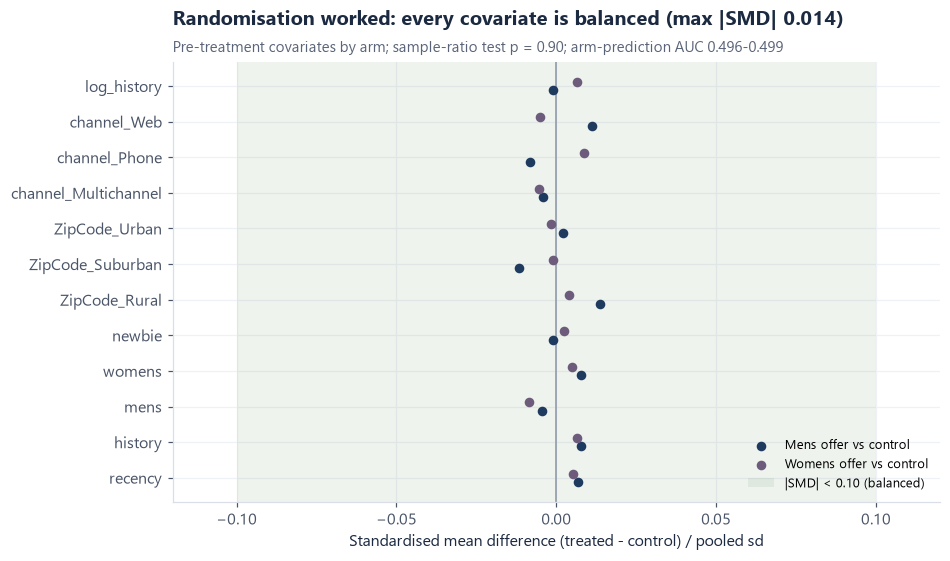

In [19]:
fig, ax = plt.subplots(figsize=(9, 5.2))
yy = np.arange(len(bal))
for t, c, off in (("Mens offer", PALETTE["navy"], -0.12), ("Womens offer", PALETTE["purple"], 0.12)):
    ax.scatter(bal[t], yy + off, color=c, s=28, label=f"{t} vs control", zorder=3)
ax.axvspan(-0.1, 0.1, color=PALETTE["sage"], alpha=0.10, lw=0, label="|SMD| < 0.10 (balanced)")
ax.axvline(0, color=PALETTE["grey"], lw=1)
ax.set_yticks(yy, bal.index); ax.set_xlim(-0.12, 0.12)
ax.set_xlabel("Standardised mean difference (treated - control) / pooled sd")
ax.legend(loc="lower right", fontsize=8.5)
headline(ax, f"Randomisation worked: every covariate is balanced (max |SMD| {bal.abs().max().max():.3f})",
         f"Pre-treatment covariates by arm; sample-ratio test p = {p_srm:.2f}; arm-prediction AUC {min(c2st.values()):.3f}-{max(c2st.values()):.3f}")
plt.show()

The test is valid: arm sizes match the 1/3 design and no covariate differs by more than a rounding error. Differences in
outcomes can be read as causal effects of the e-mails. Now the outcomes, each with a 95% interval.

In [20]:
rows = []
for a in F.ARMS:
    g = h[h["Arm"] == a]
    for metric in ("visit", "conversion"):
        k, n = g[metric].sum(), len(g)
        lo, hi = eda.wilson(k, n)
        rows.append({"arm": a, "metric": metric, "estimate": k / n, "ci_low": float(lo), "ci_high": float(hi)})
    se = g["spend"].std() / np.sqrt(len(g))
    rows.append({"arm": a, "metric": "spend", "estimate": g["spend"].mean(), "ci_low": g["spend"].mean() - 1.96 * se, "ci_high": g["spend"].mean() + 1.96 * se})
readout = pd.DataFrame(rows).set_index(["metric", "arm"])

eff = []
c = h[h["Arm"] == "Control"]
for t in F.TREATMENTS:
    g = h[h["Arm"] == t]
    for metric in ("visit", "conversion", "spend"):
        d = g[metric].mean() - c[metric].mean()
        se = np.sqrt(g[metric].var() / len(g) + c[metric].var() / len(c))
        p = stats.ttest_ind(g[metric], c[metric], equal_var=False).pvalue
        eff.append({"treatment": t, "metric": metric, "lift_vs_control": d, "ci_low": d - 1.96 * se, "ci_high": d + 1.96 * se,
                    "relative_lift": d / c[metric].mean(), "p_value": p})
effects = pd.DataFrame(eff).set_index(["treatment", "metric"])
effects

lift_vs_control  ci_low  ci_high  relative_lift  p_value
treatment    metric                                                              
Mens offer   visit                0.0766  0.0700   0.0832         0.7214   0.0000
             conversion           0.0068  0.0050   0.0086         1.1884   0.0000
             spend                0.7698  0.4851   1.0545         1.1793   0.0000
Womens offer visit                0.0452  0.0389   0.0516         0.4261   0.0000
             conversion           0.0031  0.0015   0.0047         0.5433   0.0002
             spend                0.4244  0.1690   0.6799         0.6502   0.0011

Both e-mails work, and the Mens e-mail is better on every outcome. Mens: visits +7.7 points (95% CI 7.0-8.3, a 72% relative
lift), conversion +0.68 points and spend +$0.77 per customer (0.49-1.05). Womens: visits +4.5 points and spend +$0.42
(0.17-0.68). All six effects have p < 0.002. These are average effects. Whether some customers should get the Womens
e-mail, or none, is the uplift question in notebook 03.

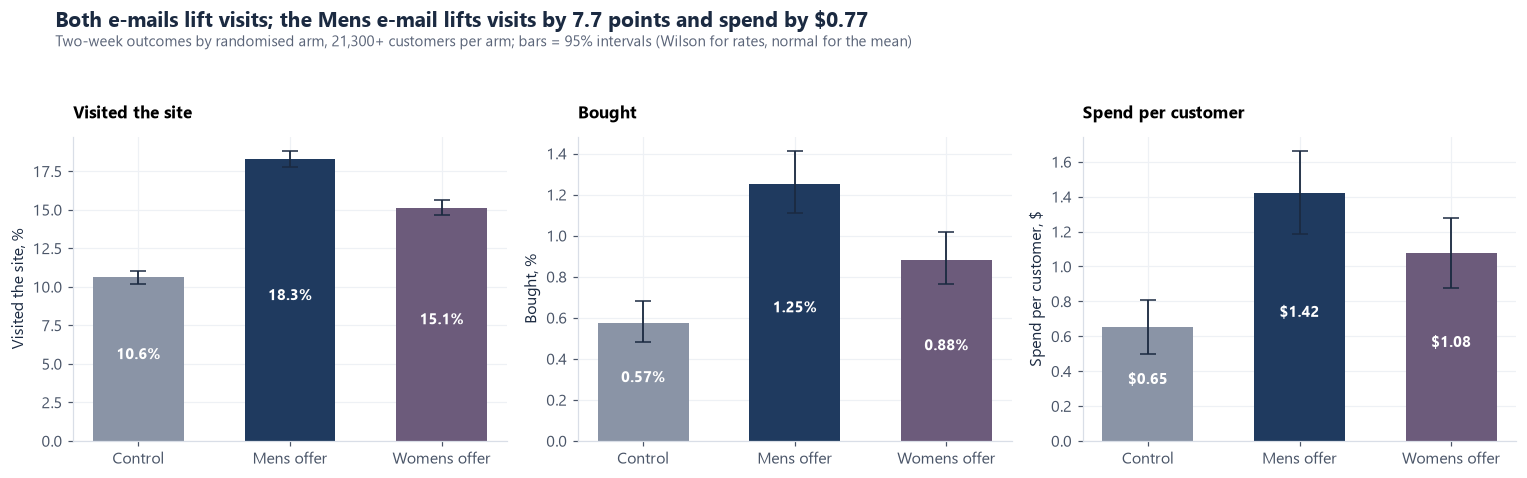

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
cols = {"Control": PALETTE["grey"], "Mens offer": PALETTE["navy"], "Womens offer": PALETTE["purple"]}
for ax, (metric, scale, unit) in zip(axes, (("visit", 100, "Visited the site, %"), ("conversion", 100, "Bought, %"), ("spend", 1, "Spend per customer, $"))):
    t = readout.loc[metric]
    ax.bar(t.index, t["estimate"] * scale, color=[cols[a] for a in t.index], width=0.6)
    ax.errorbar(np.arange(3), t["estimate"] * scale, yerr=[(t["estimate"] - t["ci_low"]) * scale, (t["ci_high"] - t["estimate"]) * scale],
                fmt="none", ecolor=PALETTE["ink"], capsize=5, lw=1.2)
    for i, v in enumerate(t["estimate"] * scale):
        ax.text(i, v * 0.5, f"${v:.2f}" if metric == "spend" else f"{v:.{2 if metric == 'conversion' else 1}f}%", ha="center", color="white",
                fontsize=10, fontweight="bold")
    ax.set_ylabel(unit); ax.set_title(unit.split(",")[0], loc="left", fontsize=11)
mv = effects.loc[("Mens offer", "visit")]
fig.suptitle(f"Both e-mails lift visits; the Mens e-mail lifts visits by {mv['lift_vs_control'] * 100:.1f} points and spend by ${effects.loc[('Mens offer', 'spend'), 'lift_vs_control']:.2f}",
             x=0.04, ha="left", fontsize=14, fontweight="bold", color=PALETTE["ink"])
fig.text(0.04, 0.905, "Two-week outcomes by randomised arm, 21,300+ customers per arm; bars = 95% intervals (Wilson for rates, normal for the mean)",
         fontsize=9.5, color="#5A6478")
fig.tight_layout(rect=(0, 0, 1, 0.9))
savefig(fig, "01-ab-readout", FIG); plt.show()

**Why spend is a hard target for individual targeting.** Spend is zero for almost everyone; a model that ranks
individuals by spend uplift has very few positive outcomes to learn from.

In [22]:
sp = h["spend"]
print(f"Customers with any spend: {(sp > 0).mean():.2%} ({(sp > 0).sum():,} of {len(h):,}); visits: {h['visit'].mean():.1%}")
print(f"Spend among buyers: median ${sp[sp > 0].median():.0f}, 90th percentile ${sp[sp > 0].quantile(0.9):.0f}, max ${sp.max():.0f}")
print(f"Coefficient of variation of spend: {sp.std() / sp.mean():.1f} (visit: {h['visit'].std() / h['visit'].mean():.1f})")

Customers with any spend: 0.90% (578 of 64,000); visits: 14.7%
Spend among buyers: median $81, 90th percentile $256, max $499
Coefficient of variation of spend: 14.3 (visit: 2.4)


578 buyers across three arms leaves about 190 per arm to learn individual spend responses from. Visit has 25 times more
positive outcomes and a coefficient of variation six times smaller, so it is the outcome that can rank individuals.

## 7. What EDA changed in the plan

* **Validate out of time and plan for a base-rate shift.** Training snapshots churn at 63%, and the test season is lower.
  Notebook 02 checks calibration on the Sep 2011 snapshot and corrects it with information known on the scoring date
  (last year's same-season base rate, 42% in Sep 2010). An isotonic fit on the spring validation snapshot cannot fix a
  seasonal shift.
* **Keep the 90-day label.** A 60-day window would call 8% of training customers churners who in fact ordered between
  day 60 and 90, which is a normal reorder gap for a wholesaler. A 120-day window cannot be observed for the Sep 2011 test
  snapshot, because the data ends on 9 Dec 2011.
* **Baselines are recency and RFM.** Recency and frequency carry most of the single-feature signal (IV 0.72 and 1.11). A
  model has to beat a recency-only rule and an RFM rule by a margin with a confidence interval, or it is not worth running.
* **Correlated families.** Six feature pairs exceed |rho| 0.75 (orders_90 and spend_90 at 0.96). Trees cope. The logistic
  baseline needs log transforms and regularisation, and SHAP credit will be split inside a family, so importance is read
  by family (recency, frequency, spend).
* **Cleaning stays as in the ETL.** Cancellations are kept (spend is net of returns). Duplicates are kept (labels are
  identical and spend rank correlation is 0.9998). Lines without a customer ID are excluded, so the model covers about
  85% of sales.
* **Experiment analysis.** Randomisation holds, so policies can be valued by inverse-propensity weighting with the known
  1/3 propensities, without modelling who opened what. Spend is too sparse to rank individuals (0.9% buyers,
  coefficient of variation 14 vs 2.4 for visit), so notebook 03 models visit uplift and values policies on spend.

In [23]:
report.update_metrics(METRICS, "01_eda", {
    "raw_lines": len(raw), "clean_lines": len(lines), "customers": int(lines["CustomerID"].nunique()),
    "share_lines_no_customer_id": float(checks["No customer ID"].mean()),
    "churn_rate_by_snapshot_90d": {f"{k:%Y-%m}": float(v) for k, v in rates["churn_90d"].dropna().items()},
    "label_flip_share_60_120": {f"{a} {b}": float(v) for (a, b), v in sens["share_flipped"].items()},
    "cohort_month1_return": float(m1), "cohort_month12_return": float(m12),
    "hillstrom_srm_p": float(p_srm), "hillstrom_max_abs_smd": float(bal.abs().max().max()),
    "hillstrom_effects": {f"{t}|{m}": {"lift": float(v["lift_vs_control"]), "ci": [float(v["ci_low"]), float(v["ci_high"])], "p": float(v["p_value"])}
                          for (t, m), v in effects.iterrows()},
})
print("metrics written")

metrics written
